In [7]:
#importing standard packages
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt

In [8]:
#importing database
df = pd.read_csv("Assignment1.csv")
df.head()

,Month,R1,R2,R3,R4,R5,R6,R7,R8,R9,...,R18,R19,R20,R21,R22,R23,R24,R25,RM-Rf,Rf
0,195001,13.20,3.46,6.95,4.43,6.48,10.29,5.22,4.23,2.35,...,2.76,2.78,8.44,0.88,0.75,2.33,1.45,5.64,1.70,0.09
1,195002,3.71,5.88,3.71,3.81,0.40,2.82,1.52,2.83,2.49,...,1.75,0.58,2.29,1.98,0.77,1.27,1.19,1.39,1.48,0.09
2,195003,-1.99,0.06,3.79,-1.96,0.18,-1.00,1.54,-0.96,-1.08,...,-0.30,-1.35,-1.16,1.97,1.62,1.57,1.73,-0.27,1.26,0.10
3,195004,10.51,3.32,8.06,5.32,7.40,8.09,5.85,5.77,4.63,...,4.46,4.53,3.62,5.35,2.39,3.19,3.73,4.30,3.94,0.09
4,195005,-2.11,2.68,-0.63,3.41,3.25,1.60,1.76,3.66,3.69,...,4.07,3.14,1.91,4.92,5.23,5.05,5.54,2.15,4.32,0.10


Assignment 1 Mean-variance Frontier

In [9]:
#assignment 1a
df_excess = df.copy()
df_excess.iloc[:,1:26] = df.iloc[:,1:26].sub(df['Rf'], axis=0)
df_excess.iloc[:,1::] = df_excess.iloc[:,1::] /100 

#generating a df of excess returns
Re = df_excess.iloc[:,1:26]

T, N = Re.shape

#generating vector of mean excess returns and sample covariance matrix
mu = Re.mean().values
Sigma = Re.cov().values

Remv = (np.linalg.inv(Sigma) @ mu) @ Re.T

mean = Remv.mean()
std = Remv.std()
sharpe = Remv.mean() / Remv.std()

print(mean)
print(std)
print(sharpe)

0.14030275031510794
0.3745700873202617
0.37457008732026026


In [10]:
#assignment 1b
y = np.ones(T)
model_star = sm.OLS(y, Re).fit()
Re_star = model_star.predict(Re).values

mean = Re_star.mean()
std = Re_star.std()
sharpe = Re_star.mean() / Re_star.std()

print(mean)
print(std)
print(sharpe)

0.1231587299320639
0.3286193195379496
0.3747762916228706


In [11]:
#assignment 1c

w = np.linalg.inv(Sigma) @ mu

print(w.shape)
print(pd.Series(w).describe())
print(w)

#answer is c. Using historical covariance often overfits, taking advantage of random sample luck leading to extreme long-short portfolios. 
#This often happens when stocks have high correlations.

(25,)
count    25.000000
mean      0.277321
std       4.139009
min      -6.957501
25%      -1.755271
50%      -0.002998
75%       3.562682
max       6.760136
dtype: float64
[-6.95750117e+00  3.03133593e-01 -1.53006178e+00  6.76013556e+00
  6.39655163e+00 -3.98297189e+00  3.56268241e+00  3.03296466e+00
 -1.29243508e+00 -6.46330704e-01 -4.43661741e+00  2.57298255e+00
 -3.42377367e+00  5.60030081e-01 -1.75966704e-01  6.31160284e+00
 -5.66816253e+00 -2.99758198e-03  3.62699464e+00 -1.75527108e+00
  5.40921322e+00 -1.68475658e+00  5.56372141e+00 -6.70484150e+00
  1.09470165e+00]


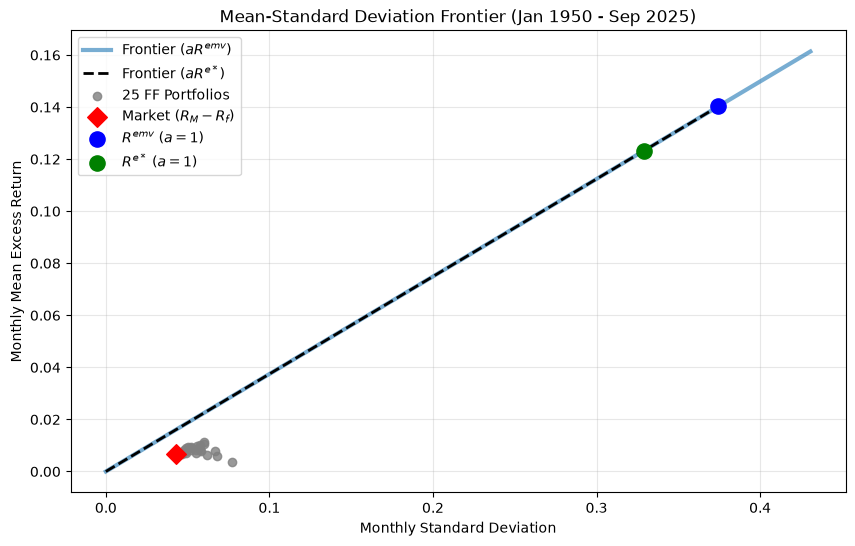

In [12]:
#assignment 1d
a_grid = np.linspace(0, 1.15, 200)

# Frontier points: mean(a * R) = a * mean(R), std(a * R) = |a| * std(R)
mv_means = a_grid * Remv.mean()
mv_stds  = np.abs(a_grid) * Remv.std(ddof=1)

star_means = a_grid * Re_star.mean()
star_stds  = np.abs(a_grid) * Re_star.std(ddof=1)

mkt_ex = df_excess["RM-Rf"]

plt.figure(figsize=(10, 6))
# Plot frontiers (they lie directly on top of each other because they have the exact same Sharpe ratio!)
plt.plot(mv_stds, mv_means, label='Frontier ($a R^{emv}$)', linewidth=3, alpha=0.6)
plt.plot(star_stds, star_means, '--', label='Frontier ($a R^{e*}$)', linewidth=2, color='black')

# Plot 25 test assets
plt.scatter(Re.std(ddof=1), Re.mean(), color='gray', alpha=0.8, label='25 FF Portfolios')

# Plot Excess Market Return
plt.scatter(mkt_ex.std(ddof=1), mkt_ex.mean(), color='red', s=100, marker='D', label='Market ($R_M - R_f$)')

# Highlight R^{emv} and R^{e*}
plt.scatter(Remv.std(ddof=1), Remv.mean(), color='blue', s=120, zorder=5, label='$R^{emv}$ ($a=1$)')
plt.scatter(Re_star.std(ddof=1), Re_star.mean(), color='green', s=120, zorder=5, label='$R^{e*}$ ($a=1$)')

plt.title('Mean-Standard Deviation Frontier (Jan 1950 - Sep 2025)')
plt.xlabel('Monthly Standard Deviation')
plt.ylabel('Monthly Mean Excess Return')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()